# Лабораторная №2. Устойчивость параметров модели

Используем остаточный бутстреп, зашумление с учётом условного
распределения и расстояние Вассерштейна — Добрушина $W_1$.
Исследуем изменение распределений оценок коэффициентов после добавления
шума и проверяем возможность удаления слагаемых модели.

## 1. Модель и параметры первой лабораторной

В первой работе рассчитаны электромагнитные поля, рассеяние на сфере
и токи двух связанных RLC-контуров. В уравнениях полей $\epsilon$
задаёт диэлектрическую проницаемость, $\mu$ — магнитную проницаемость,
$\sigma$ — проводимость среды. В задаче рассеяния заданы радиус сферы
и показатель преломления материала $n(\lambda)$.

Для основной части второй работы используем модель контуров
считывателя (`reader`) и метки (`tag`):

$$
\begin{bmatrix}L_1&M\\M&L_2\end{bmatrix}\dot i
+\operatorname{diag}(R_1,R_2)i
+\operatorname{diag}(1/C_1,1/C_2)q
=\begin{bmatrix}\cos(\omega t)\\0\end{bmatrix},
\qquad \dot q=i.
$$

| Обозначение | Смысл | Использование |
|---|---|---|
| $M$ | Взаимная индуктивность катушек, нГн | Оцениваем по току $i_2(t)$ |
| $R_2$ | Сопротивление вторичного контура, Ом | Оцениваем по току $i_2(t)$ |
| $L_1,L_2$ | Собственные индуктивности | Известны: 1 и 0.5 мкГн |
| $R_1$ | Сопротивление первого контура | Известно: 2 Ом |
| $f$ | Частота возбуждения | Известна: 13.56 МГц |
| $C_1,C_2$ | Ёмкости контуров | Рассчитаны как $C_j=1/(\omega^2L_j)$ |
| $i_1,i_2,q_1,q_2$ | Токи и заряды | Переменные состояния системы |

В первой работе взаимная индуктивность также вычислена по геометрии
катушек: $M_{true}=3.7673$ нГн. Для генерации тока принято $R_2=4$ Ом.
Восстанавливаем вектор $\theta=(M,R_2)$ по зашумлённым наблюдениям.
Начальное состояние нулевое, интервал времени — 0–2 мкс.
Каждая третья точка отложена для проверки.

## 2. Окружение и настройки

Настройки эксперимента и физические константы находятся в
`src/emlab/lab2_config.py`. Первая ячейка проверяет выбранное ядро.


In [1]:
from pathlib import Path

from emlab.lab2_runtime import configure_matplotlib_cache

ROOT = Path.cwd()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
configure_matplotlib_cache(ROOT)

WindowsPath('C:/Users/fedor/Desktop/X-Files/Programming/11 сем/ФАД/lab2/tmp/matplotlib')

In [2]:
from emlab import (
    lab2_data,
    lab2_experiment,
    lab2_plots,
    lab2_reporting,
)
from emlab.lab2_config import DEFAULT_CONFIG

CONFIG = DEFAULT_CONFIG

lab2_reporting.show_environment(ROOT, CONFIG)

Python: C:\Users\fedor\Desktop\X-Files\Programming\11 сем\ФАД\lab2\.venv\Scripts\python.exe


{'seed': 20261029,
 'bootstrap_replicates': 300,
 'intervention_repeats': 5,
 'levels': (0.0, 0.5, 1.0, 2.0, 4.0),
 'losses': ('linear', 'soft_l1'),
 'example_alpha': 2.0,
 'example_repeat': 0,
 'confidence_quantiles': (0.025, 0.975),
 'material_train_points': 160,
 'material_validation_points': 81,
 'rlc_relative_tolerance': 0.05,
 'material_tolerance': 0.0002,
 'max_boundary_fraction': 0.05,
 'notebook_timeout_seconds': 7200}

## 3. Подготовка данных

Загружаем синтетические токи из первой работы и два источника
дисперсии: кварцевое стекло и воду. Для оптики оцениваем амплитуды
формулы Зельмейера при фиксированных резонансах:

$$n^2(\lambda)-1=\sum_j a_j\frac{\lambda^2}{\lambda^2-b_j}.$$

Для стекла используем 0.25–3.5 мкм, для воды — 0.2–1.1 мкм;
160 точек для обучения и 81 точку для проверки. К значениям опубликованных
формул добавляем нормальную ошибку с масштабом
$s(\lambda)=2\cdot10^{-5}(1+\lambda/\lambda_{max})$.

Дополнительно создаём `silica_offset`: те же данные стекла подгоняются
моделью с дополнительным свободным коэффициентом $c_0$:

$$n^2(\lambda)-1=c_0+\sum_j a_j\frac{\lambda^2}{\lambda^2-b_j}.$$

При генерации данных $c_0=0$. Этот пример используется для проверки
удаления избыточного слагаемого.


In [3]:
datasets = lab2_data.prepare_datasets(ROOT, CONFIG)
lab2_reporting.show_datasets(datasets)

|Набор|Обучение|Проверка|Коэффициенты|
|---|---|---|---|
|rlc|334|167|M [nH], R2 [ohm]|
|silica|160|81|a1, a2, a3|
|water|160|81|a1, a2, a3, a4|
|silica_offset|160|81|a1, a2, a3, c0|

## 4. Методы эксперимента

**Бутстреп.** Подгоняем модель и центрируем нормированные остатки
$r_i=(y_i-f(x_i;\hat\theta))/s_i$. Выбираем остатки с возвращением,
строим $y_i^*=f(x_i;\hat\theta)+s_ir_{k_i}$ и заново оцениваем
все коэффициенты. Выполняем 300 повторений при фиксированных $x_i$.
По каждому коэффициенту получаем распределение оценок и интервал
по квантилям 2.5% и 97.5%. Предполагаем независимость нормированных ошибок.

**Интервенция.** При условном распределении
$Y\mid X\sim N(f_\theta(X),s(X)^2)$ добавляем шум:

$$Y_\alpha=Y+\alpha s(X)Z,\qquad Z\sim N(0,1).$$

Условная дисперсия становится $(1+\alpha^2)s(X)^2$.
Используем $\alpha\in\{0,0.5,1,2,4\}$ и пять реализаций шума.
Для каждой изменённой выборки повторяем подгонку и бутстреп.
Масштаб $s(X)$ фиксируем по исходному эксперименту.

**Расстояние.** Сравниваем распределения каждого коэффициента отдельно:

$$W_1(P_j,Q_j)=\int|F_{P_j}(u)-F_{Q_j}(u)|\,du.$$

Дополнительно делим расстояние на стандартное отклонение исходных
бутстреп-оценок. Сравниваем квадратичную функцию ошибки `linear`
и робастную `soft_l1` с фиксированным масштабом нормированных остатков.

Расчёты выполняются в `lab2_experiment.py`, статистические методы —
в `intervention.py`. Токи вычисляются точным решением линейной RLC-системы.


In [4]:
results = lab2_experiment.run_experiment(ROOT, datasets, CONFIG)

Loaded saved bootstrap draws (inputs and configuration verified).


## 5. Распределения коэффициентов

Гистограммы сравнивают исходные бутстреп-оценки и оценки после
интервенции с $\alpha=2$ для первой реализации дополнительного шума.
Строки соответствуют двум функциям ошибки.


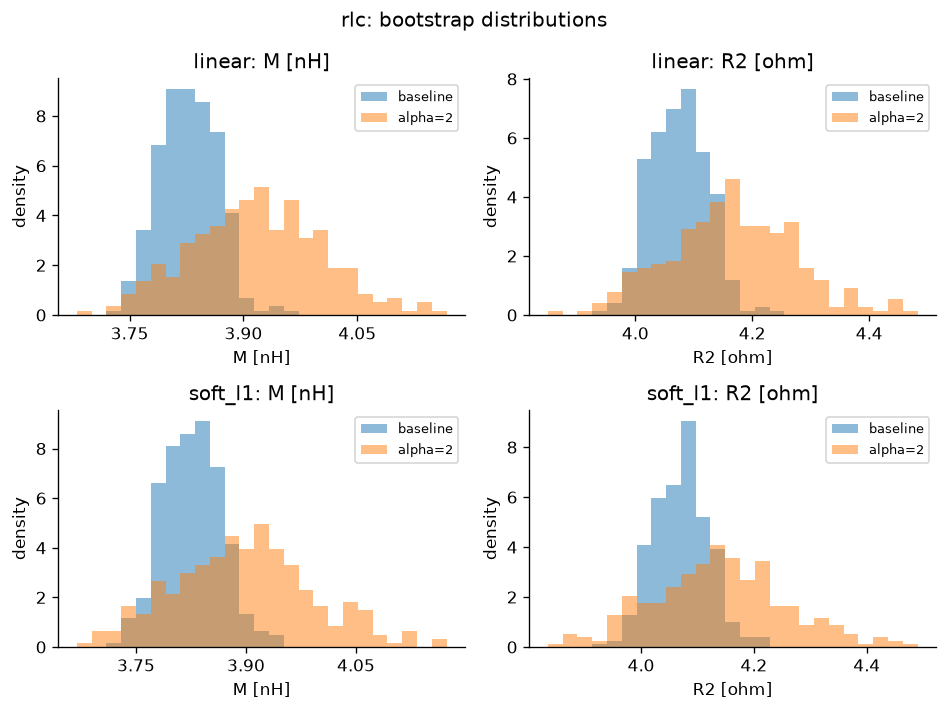

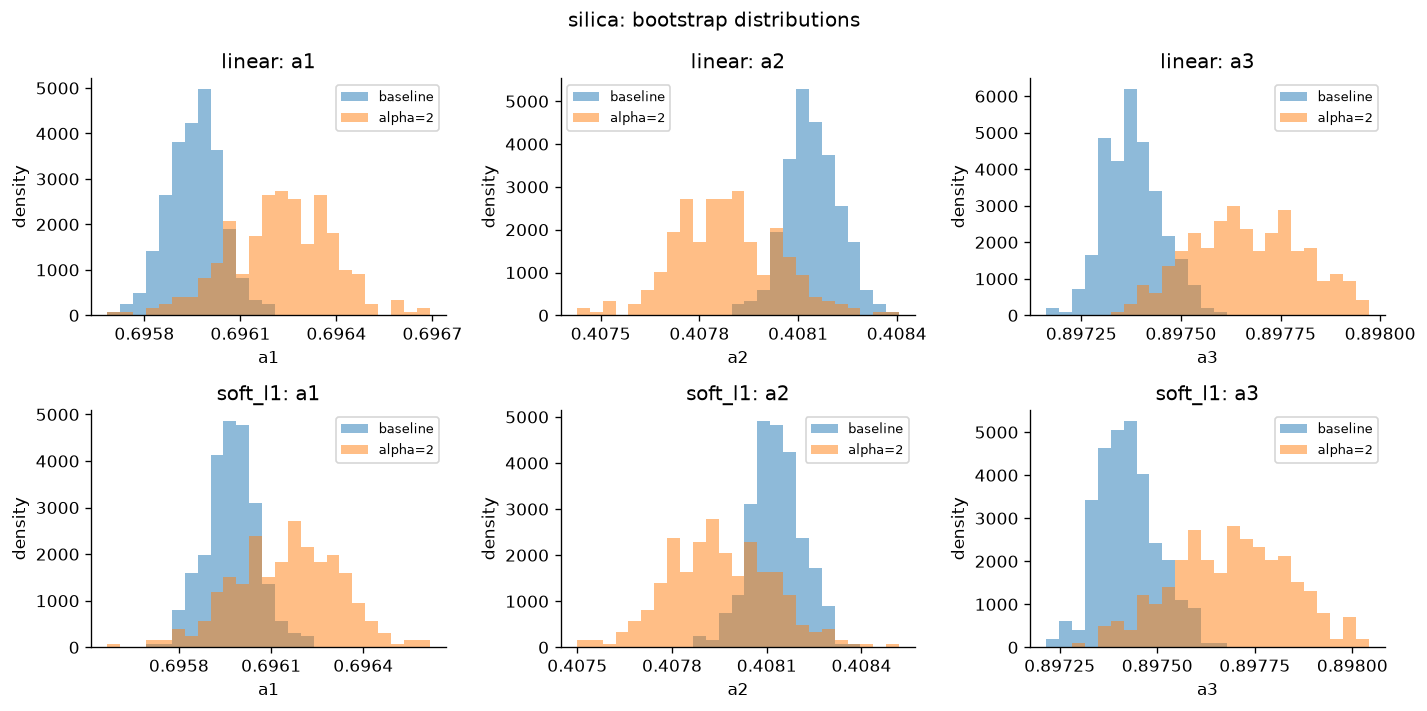

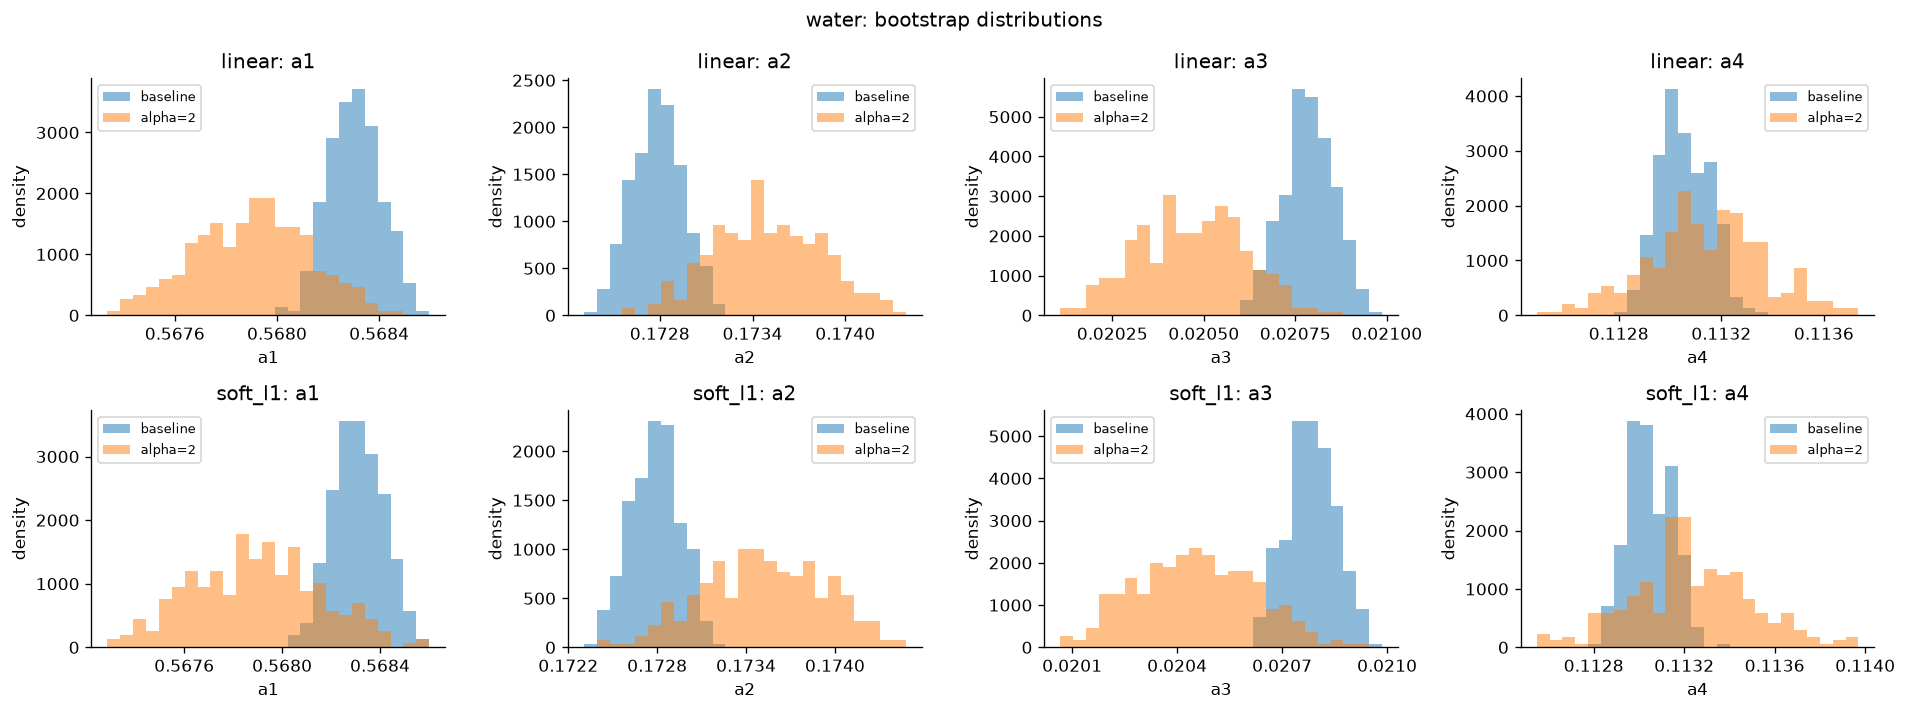

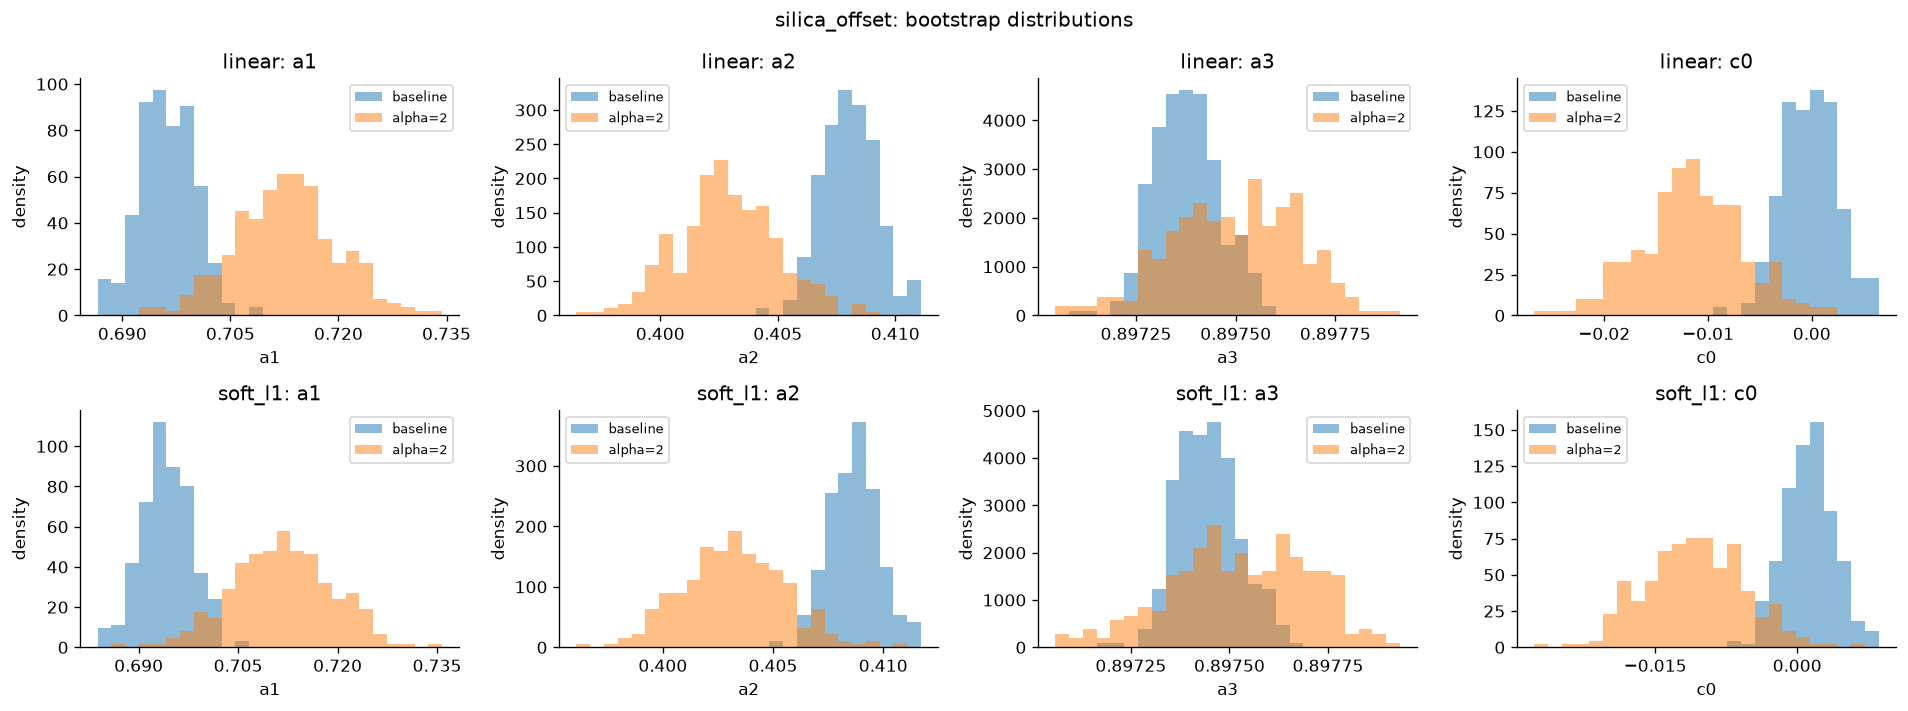

In [5]:
lab2_plots.plot_distributions(results)

## 6. Расстояния и зависимость от уровня шума

Строим среднее нормированное $W_1$ по пяти реализациям интервенции.
Затенение показывает минимум и максимум этих пяти значений.
В таблице приведены исходные оценки, 95% бутстреп-интервалы
и среднее расстояние при $\alpha=2$ в единицах коэффициента.


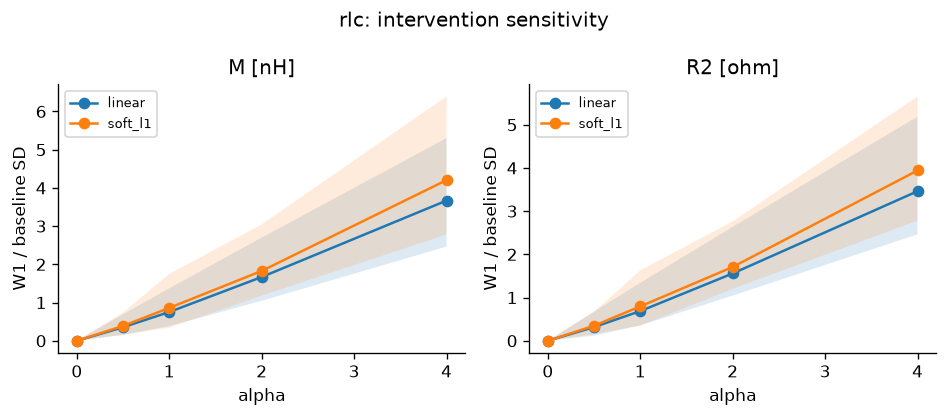

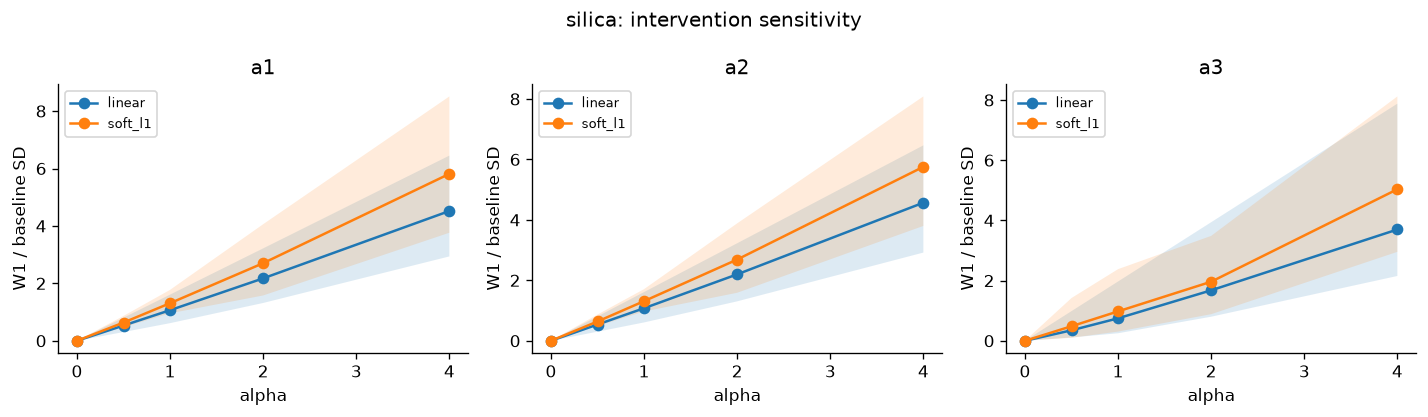

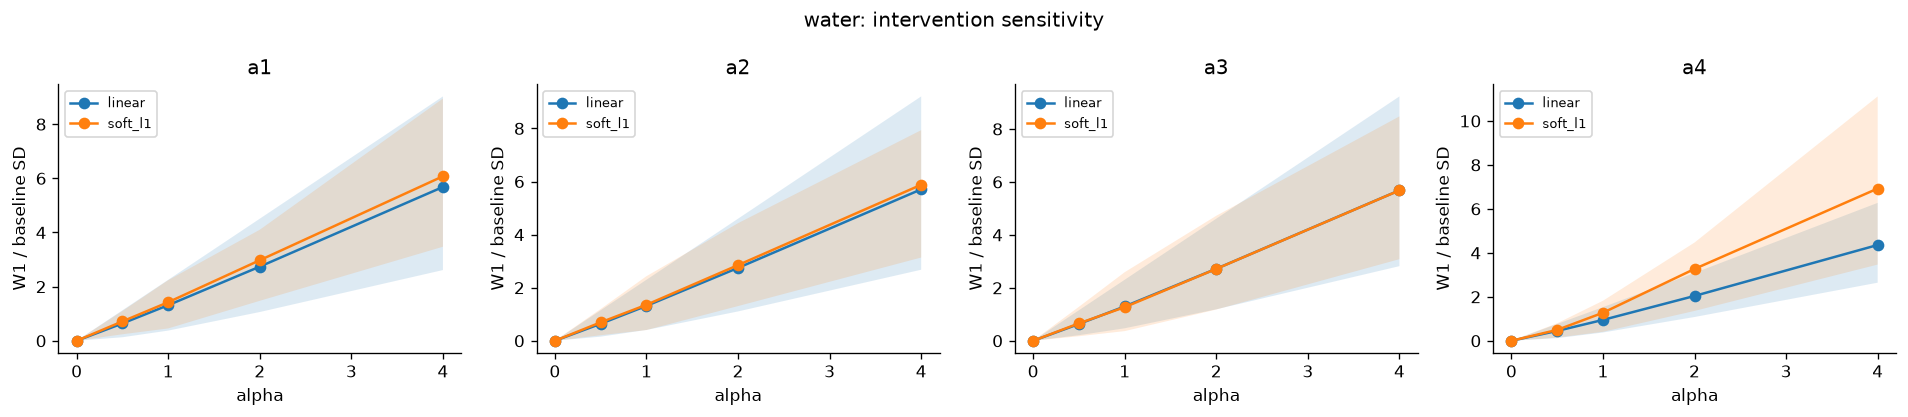

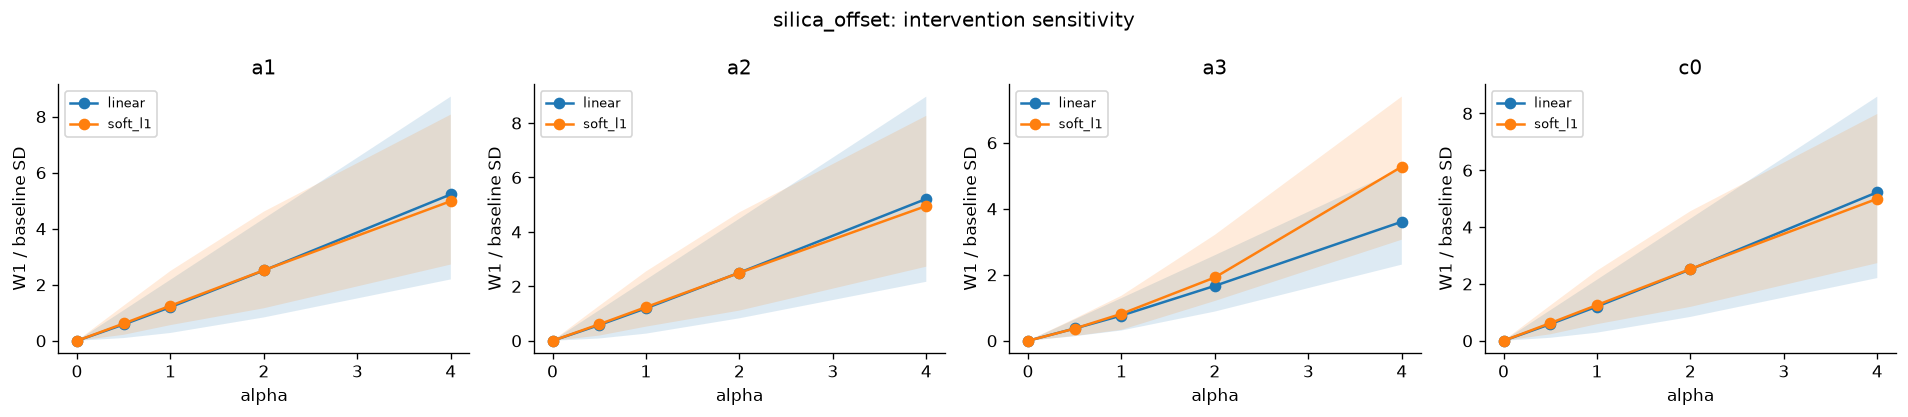

|Набор|Потери|Параметр|Оценка|95% интервал|W1|
|---|---|---|---|---|---|
|rlc|linear|M [nH]|3.82617|[3.75807; 3.89621]|0.0650276|
|rlc|linear|R2 [ohm]|4.07297|[3.98788; 4.16078]|0.0759046|
|rlc|soft_l1|M [nH]|3.82441|[3.75037; 3.89989]|0.0726275|
|rlc|soft_l1|R2 [ohm]|4.06847|[3.97641; 4.16418]|0.0849183|
|silica|linear|a1|0.695955|[0.695791; 0.69612]|0.000180807|
|silica|linear|a2|0.408147|[0.407988; 0.408308]|0.00017714|
|silica|linear|a3|0.897378|[0.897248; 0.897524]|0.00012198|
|silica|soft_l1|a1|0.695975|[0.695803; 0.696149]|0.000230177|
|silica|soft_l1|a2|0.408128|[0.407958; 0.408295]|0.000221612|
|silica|soft_l1|a3|0.897421|[0.897293; 0.897591]|0.00014815|
|water|linear|a1|0.568297|[0.568109; 0.5685]|0.000282687|
|water|linear|a2|0.172801|[0.172474; 0.173093]|0.000454854|
|water|linear|a3|0.0207804|[0.0206539; 0.0209158]|0.000188685|
|water|linear|a4|0.113049|[0.112882; 0.113239]|0.000199999|
|water|soft_l1|a1|0.568302|[0.568124; 0.56851]|0.000305554|
|water|soft_l1|a2|0.1728|[0.172464; 0.173094]|0.000470872|
|water|soft_l1|a3|0.0207766|[0.0206532; 0.0209206]|0.000188431|
|water|soft_l1|a4|0.113045|[0.112877; 0.113228]|0.000320939|
|silica_offset|linear|a1|0.696355|[0.687932; 0.703143]|0.00950293|
|silica_offset|linear|a2|0.408026|[0.405937; 0.410593]|0.00288303|
|silica_offset|linear|a3|0.897374|[0.897231; 0.897537]|0.000134|
|silica_offset|linear|c0|-0.000279501|[-0.00498938; 0.00549665]|0.00662934|
|silica_offset|soft_l1|a1|0.694269|[0.686181; 0.701392]|0.00957168|
|silica_offset|soft_l1|a2|0.408644|[0.406476; 0.411105]|0.00288951|
|silica_offset|soft_l1|a3|0.89744|[0.897308; 0.897608]|0.000154683|
|silica_offset|soft_l1|c0|0.00119153|[-0.00376618; 0.00676595]|0.00669477|

In [6]:
lab2_plots.plot_distances(results)
lab2_reporting.show_parameter_summary(results)

Совместные облака показывают зависимость оценок
$M$ и $R_2$ до и после интервенции.


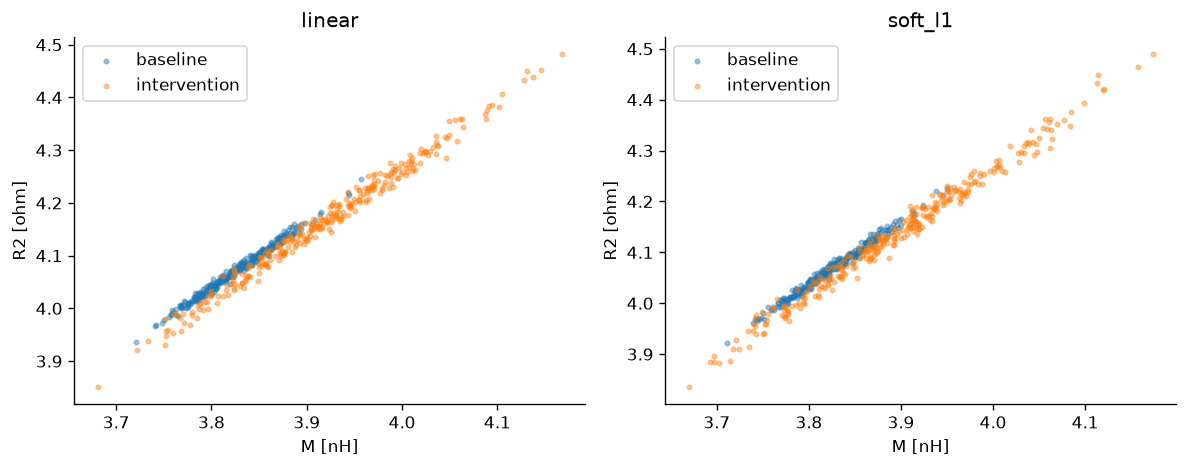

In [7]:
lab2_plots.plot_joint_rlc(results)

## 7. Соответствие параметров элементам графа

Для выбранной модели строим граф контуров. Общий коэффициент $M$
соответствует двум взаимным связям `reader` ↔ `tag`.
$R_2$ задаёт потери во вторичном контуре и изображается петлёй.
Для оптики каждый $a_j$ задаёт ветвь резонансного вклада,
а $c_0$ — дополнительную постоянную ветвь суммы.


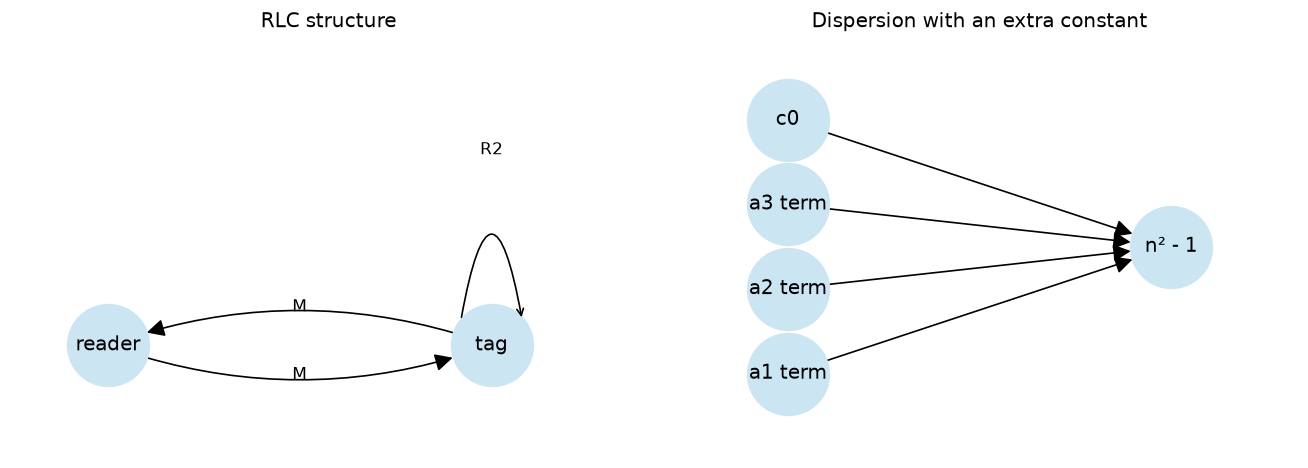

In [8]:
lab2_plots.plot_structure(results)

## 8. Проверка удаления слагаемых

По очереди зануляем коэффициенты и повторно оцениваем оставшиеся
параметры с квадратичной ошибкой. Для $M=0$ ток второго контура равен нулю.
Потери проверяем при практически нулевом $R_2=10^{-6}$ Ом.

На отложенной сетке вычисляем
$\Delta RMSE=RMSE_{reduced}-RMSE_{full}$.
Удаляем слагаемое, если $\Delta RMSE\leq\tau$
и доля бутстреп-оценок на границах не превышает 5%.
Допуск для тока — 5% его максимальной чистой амплитуды;
для оптики — $2\cdot10^{-4}$ в $n^2-1$.
В таблице показаны результаты применения этого правила.


In [9]:
lab2_reporting.show_decisions(results)

|Набор|Параметр|RMSE full|RMSE reduced|ΔRMSE|Допуск|Решение|
|---|---|---|---|---|---|---|
|rlc|M [nH]|2.739e-05|0.01498|0.01495|0.00162|СОХРАНИТЬ|
|rlc|R2 [ohm]|2.739e-05|0.003609|0.003581|0.00162|СОХРАНИТЬ|
|silica|a1|5.661e-06|0.01813|0.01813|0.0002|СОХРАНИТЬ|
|silica|a2|5.661e-06|0.01091|0.01091|0.0002|СОХРАНИТЬ|
|silica|a3|5.661e-06|0.03575|0.03574|0.0002|СОХРАНИТЬ|
|water|a1|2.934e-06|0.05917|0.05916|0.0002|СОХРАНИТЬ|
|water|a2|2.934e-06|0.002185|0.002183|0.0002|СОХРАНИТЬ|
|water|a3|2.934e-06|0.0006374|0.0006345|0.0002|СОХРАНИТЬ|
|water|a4|2.934e-06|0.003082|0.003079|0.0002|СОХРАНИТЬ|
|silica_offset|a1|5.664e-06|0.01441|0.0144|0.0002|СОХРАНИТЬ|
|silica_offset|a2|5.664e-06|0.009757|0.009752|0.0002|СОХРАНИТЬ|
|silica_offset|a3|5.664e-06|0.0357|0.0357|0.0002|СОХРАНИТЬ|
|silica_offset|c0|5.664e-06|5.661e-06|-3.384e-09|0.0002|УДАЛИТЬ|

### Пример избыточного параметра

Для $c_0$ показываем оценку, бутстреп-интервал и решение по тому же
правилу. На графике сравниваем ошибку полной модели `silica_offset`
и модели с $c_0=0$ после повторной подгонки амплитуд.


|Параметр|Истинное значение|Оценка|95% интервал|ΔRMSE|Допуск|Решение|
|---|---|---|---|---|---|---|
|c0|0|-0.000279501|[-0.00498938; 0.00549665]|-3.384e-09|0.0002|УДАЛИТЬ|

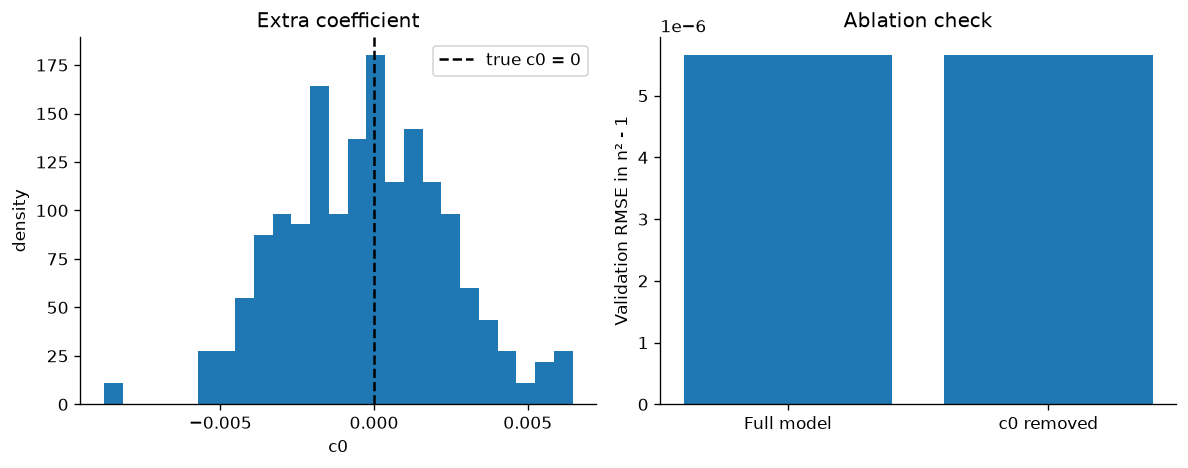

In [10]:
lab2_reporting.show_offset_example(results)
lab2_plots.plot_offset_example(results)

## Источники

- Efron (1979). Bootstrap Methods: Another Look at the Jackknife.
  https://doi.org/10.1214/aos/1176344552
- SciPy: одномерное расстояние Вассерштейна.
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html
- Malitson (1965): дисперсия кварцевого стекла.
  https://doi.org/10.1364/JOSA.55.001205
- Daimon, Masumura (2007): дисперсия воды.
  https://doi.org/10.1364/AO.46.003811
- Исходная лабораторная и физическая модель:
  https://github.com/KasiukVadim/iad_fall_2026
  https://doi.org/10.1038/s41598-023-39825-9

HTTP-адреса данных сохранены в `data/provenance.json`.
Описание использования ИИ — `docs/AI_USAGE_LAB2.md`.
